### XGBoost observational data
Sampled from YAHPO Gym [https://github.com/slds-lmu/yahpo_gym]

In [1]:
import pandas as pd

df = pd.read_csv('HPOXGBoost_observational_data.csv')
df.head()

,alpha,colsample_bylevel,colsample_bytree,eta,gamma,lambda,max_depth,min_child_weight,nrounds,rate_drop,skip_drop,subsample,mmce,nf,ias,rammodel
0,0.268092,0.374519,0.715221,0.031498,0.543084,0.392910,13.037393,128.043151,1878.211707,0.602305,0.689922,0.205579,-0.479428,-18.0,-0.000533,-1.289984
1,0.799646,0.693020,0.049070,0.714544,0.025425,0.721804,2.251990,32.364600,134.110280,0.111130,0.007990,0.880699,-0.130095,-20.0,-0.002140,-0.412221
2,0.642815,0.249758,0.846800,0.461576,0.418256,0.850313,9.926907,70.420725,890.560835,0.472426,0.406617,0.773136,-0.077729,-20.0,-0.028850,-0.914460
3,0.174812,0.813624,0.397264,0.777618,0.900035,0.022339,6.784135,93.450062,1137.369405,0.994923,0.853715,0.547816,-0.084785,-20.0,-0.023628,-0.670339
4,0.003142,0.118571,0.153280,0.977597,0.798265,0.298476,8.866140,40.319103,646.754617,0.198435,0.288795,0.429742,-0.089858,-20.0,-0.035001,-0.731920


In [2]:
# All columns except last four are design variables
design_variables = df.columns.tolist()[:-4]
kpi_constraints_variables = df.columns.tolist()[-3:]
objective_variables = df.columns.tolist()[-4:-3]

In [3]:
design_variables

['alpha',
 'colsample_bylevel',
 'colsample_bytree',
 'eta',
 'gamma',
 'lambda',
 'max_depth',
 'min_child_weight',
 'nrounds',
 'rate_drop',
 'skip_drop',
 'subsample']

In [4]:
kpi_constraints_variables

['nf', 'ias', 'rammodel']

In [5]:
objective_variables

['mmce']

### Causal discovery using FCI

Enforece structural constraints, outcome var do not cause design var.

In [6]:
forbidden_edges = []
outcome_variables = kpi_constraints_variables + objective_variables
# outcome_variables --> design_variables
for opt in design_variables:
    for cur_elem in outcome_variables:
        if cur_elem != opt:
            forbidden_edges.append((cur_elem, opt))


In [7]:
from rescue_cpm.causal_model import CausalPerformanceModel

cpm = CausalPerformanceModel(
    data=df,
    is_design_var_independent=True,
    use_default_bk=False,
    forbidden_edges=forbidden_edges,
    design_variables=design_variables,
    objective_variables=objective_variables,
    kpi_and_constraints_variables=kpi_constraints_variables,
)
G = cpm.learn(causal_discovery="FCI")

/home/abir/care/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


X8 --> X16
Starting BK Orientation.
Orienting edge (Knowledge): X2 --> X14
Orienting edge (Knowledge): X3 --> X15
Orienting edge (Knowledge): X4 --> X15
Orienting edge (Knowledge): X7 --> X16
Orienting edge (Knowledge): X8 --> X14
Orienting edge (Knowledge): X8 --> X15
Orienting edge (Knowledge): X8 --> X16
Orienting edge (Knowledge): X9 --> X16
Orienting edge (Knowledge): X10 --> X16
Orienting edge (Knowledge): X11 --> X15
Orienting edge (Knowledge): X11 --> X16
Orienting edge (Knowledge): X12 --> X13
Orienting edge (Knowledge): X12 --> X15
Finishing BK Orientation.
Starting BK Orientation.
Orienting edge (Knowledge): X2 --> X14
Orienting edge (Knowledge): X3 --> X15
Orienting edge (Knowledge): X4 --> X15
Orienting edge (Knowledge): X7 --> X16
Orienting edge (Knowledge): X8 --> X14
Orienting edge (Knowledge): X8 --> X15
Orienting edge (Knowledge): X8 --> X16
Orienting edge (Knowledge): X9 --> X16
Orienting edge (Knowledge): X10 --> X16
Orienting edge (Knowledge): X11 --> X15
Orienting

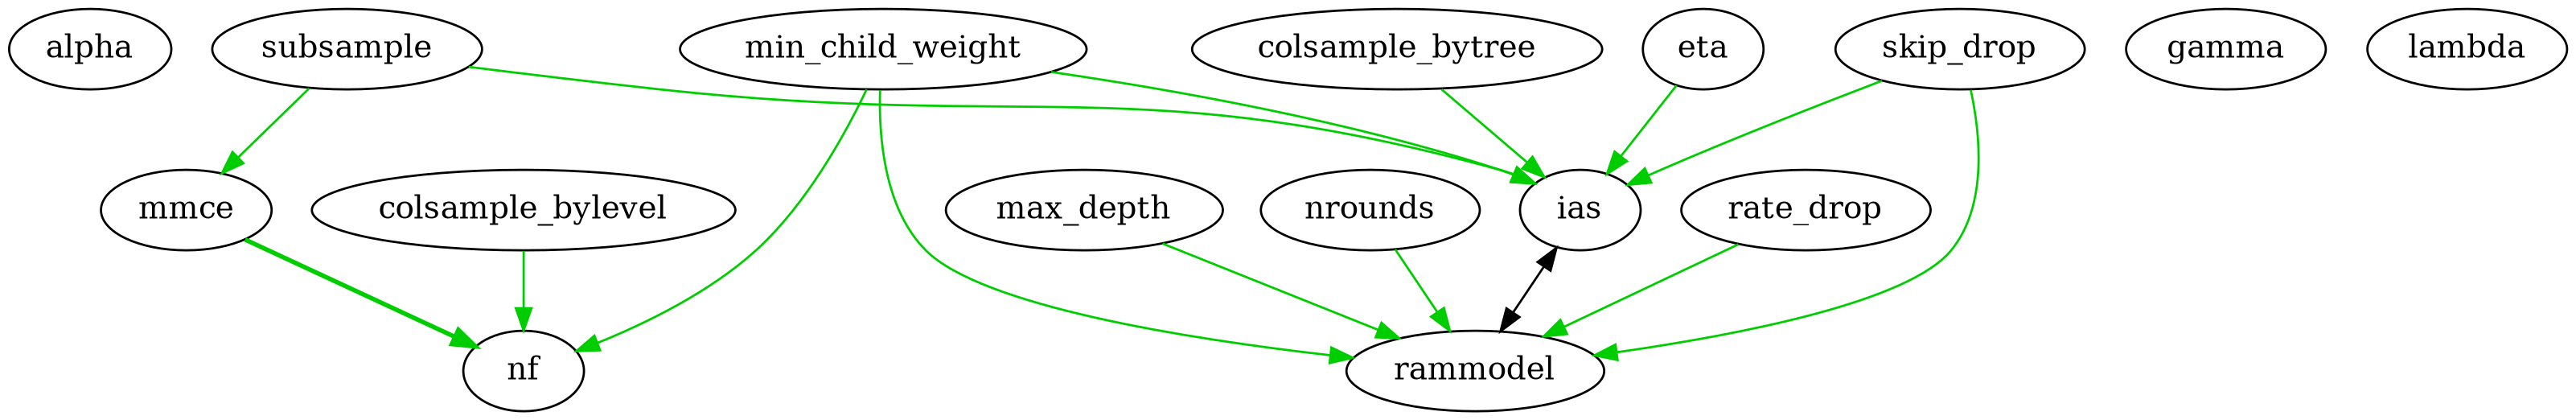

In [8]:
import pydot
from IPython.display import Image

dot_data = G.to_string()
(dot_graph,) = pydot.graph_from_dot_data(dot_data)
png_data = dot_graph.create_png()
Image(png_data)

### Demonstrating Entropy based edge resolution
To get some partial edges we removed the structural constraints.

In [ ]:
cpm = CausalPerformanceModel(
    data=df,
    is_design_var_independent=True,
    use_default_bk=False,
    forbidden_edges=None,   # No forbidden edges
    design_variables=design_variables,
    objective_variables=objective_variables,
    kpi_and_constraints_variables=kpi_constraints_variables,
)
G = cpm.learn(causal_discovery="FCI", save_raw_fci_graph=True)  # save the raw FCI graph

X8 --> X16
X8 --> X16


#### FCI generated PAG

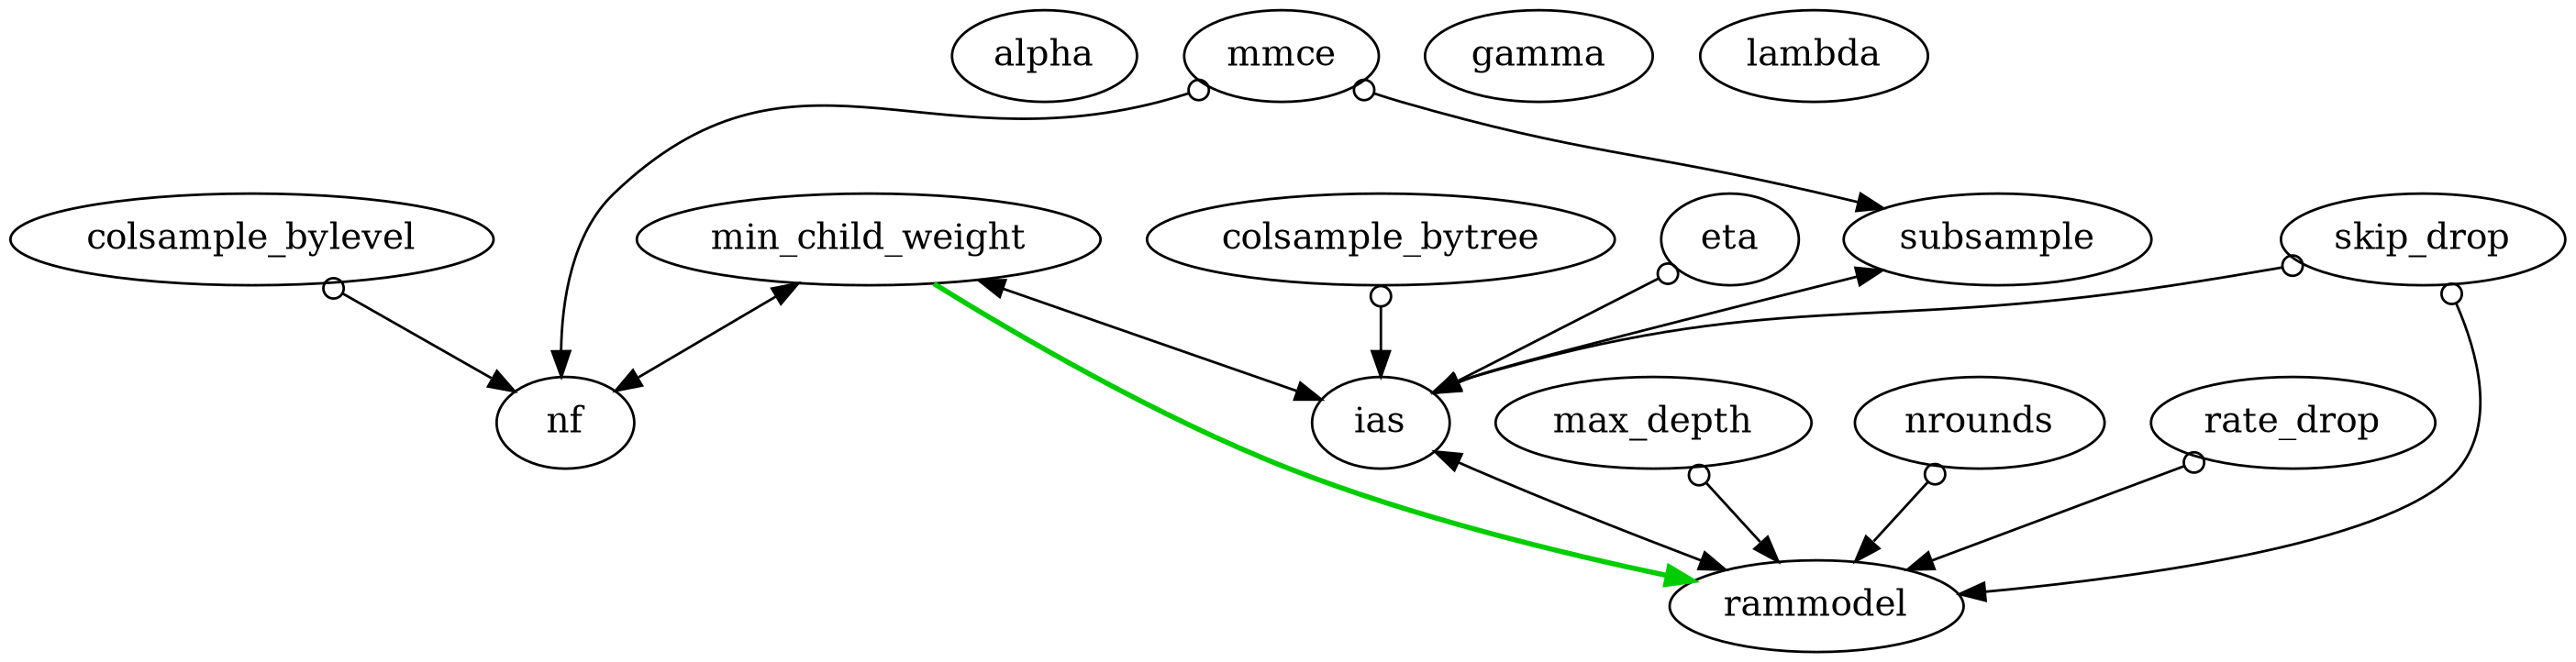

In [10]:
Image("FCI.png")

#### Resolved graph

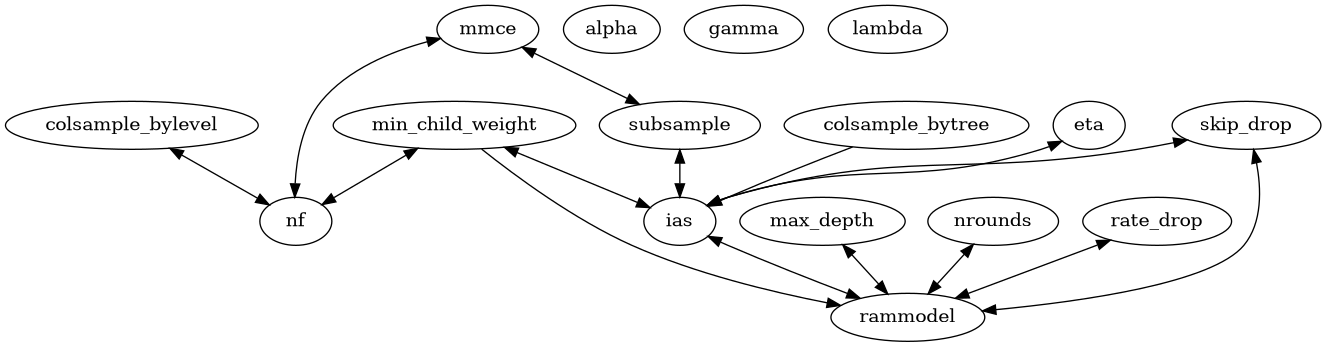

In [11]:
dot_data = G.to_string()
(dot_graph,) = pydot.graph_from_dot_data(dot_data)
png_data = dot_graph.create_png()
Image(png_data)